# Монте-Карло проверка статистических методов A/B-тестирования

Проверяю на симуляциях, как ведут себя обычные критерии A/B-тестов там, где их чаще всего
применяют неправильно: малые выборки, подглядывание, тяжёлые хвосты, метрики-отношения,
много метрик сразу, сломанное разбиение. В конце - разбор реального теста Cookie Cats.

Все цифры берутся
SQL-запросами из `sql/simulations` к результатам симуляций (`results/*.parquet`),
графики строятся командой `make figures`.

Общие договорённости: двусторонние тесты, $\alpha = 0.05$. Каждая доля из симуляции
приводится с 95% интервалом Уилсона: при R = 10 000 и истинных 5% это $\pm 0.43$ п.п.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image, display

from abtest_sim import corrections, db, power
from abtest_sim import cookie_cats as cc

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)

con = db.connect()
rates = db.query("simulations/01_reject_rates", con)


def show(name):
    display(Image(filename=f"../figures/{name}.png"))

## 1. A/A-тесты: держит ли критерий 5%

В каждом из 10 000 экспериментов эффекта нет, поэтому доля p < 0,05 - это доля
ложных срабатываний (FPR). Корректный критерий должен давать 5% $\pm$ 0,43 п.п.

In [2]:
aa = rates.query("scenario == 'aa'")
aa.pivot_table(index=["metric", "test"], columns="n_per_group", values="rate")

n_per_group               50      100     500     1000    10000
metric     test                                                
conversion bootstrap     0.0475  0.0420  0.0450  0.0480  0.0450
           welch_t       0.0469  0.0539  0.0430  0.0519  0.0510
           z_test        0.0492  0.0539  0.0433  0.0519  0.0510
ctr        bootstrap     0.0575  0.0475  0.0450  0.0595  0.0520
           delta         0.0562  0.0508  0.0503  0.0479  0.0490
           naive_t       0.0937  0.0896  0.0905  0.0910  0.0927
pre_period bootstrap     0.0550  0.0555  0.0550  0.0480  0.0495
           cuped         0.0526  0.0493  0.0509  0.0513  0.0500
           welch_t       0.0485  0.0516  0.0487  0.0481  0.0509
revenue    bootstrap     0.0910  0.0800  0.0605  0.0605  0.0505
           mann_whitney  0.0448  0.0502  0.0492  0.0511  0.0523
           welch_t       0.0189  0.0293  0.0421  0.0460  0.0505

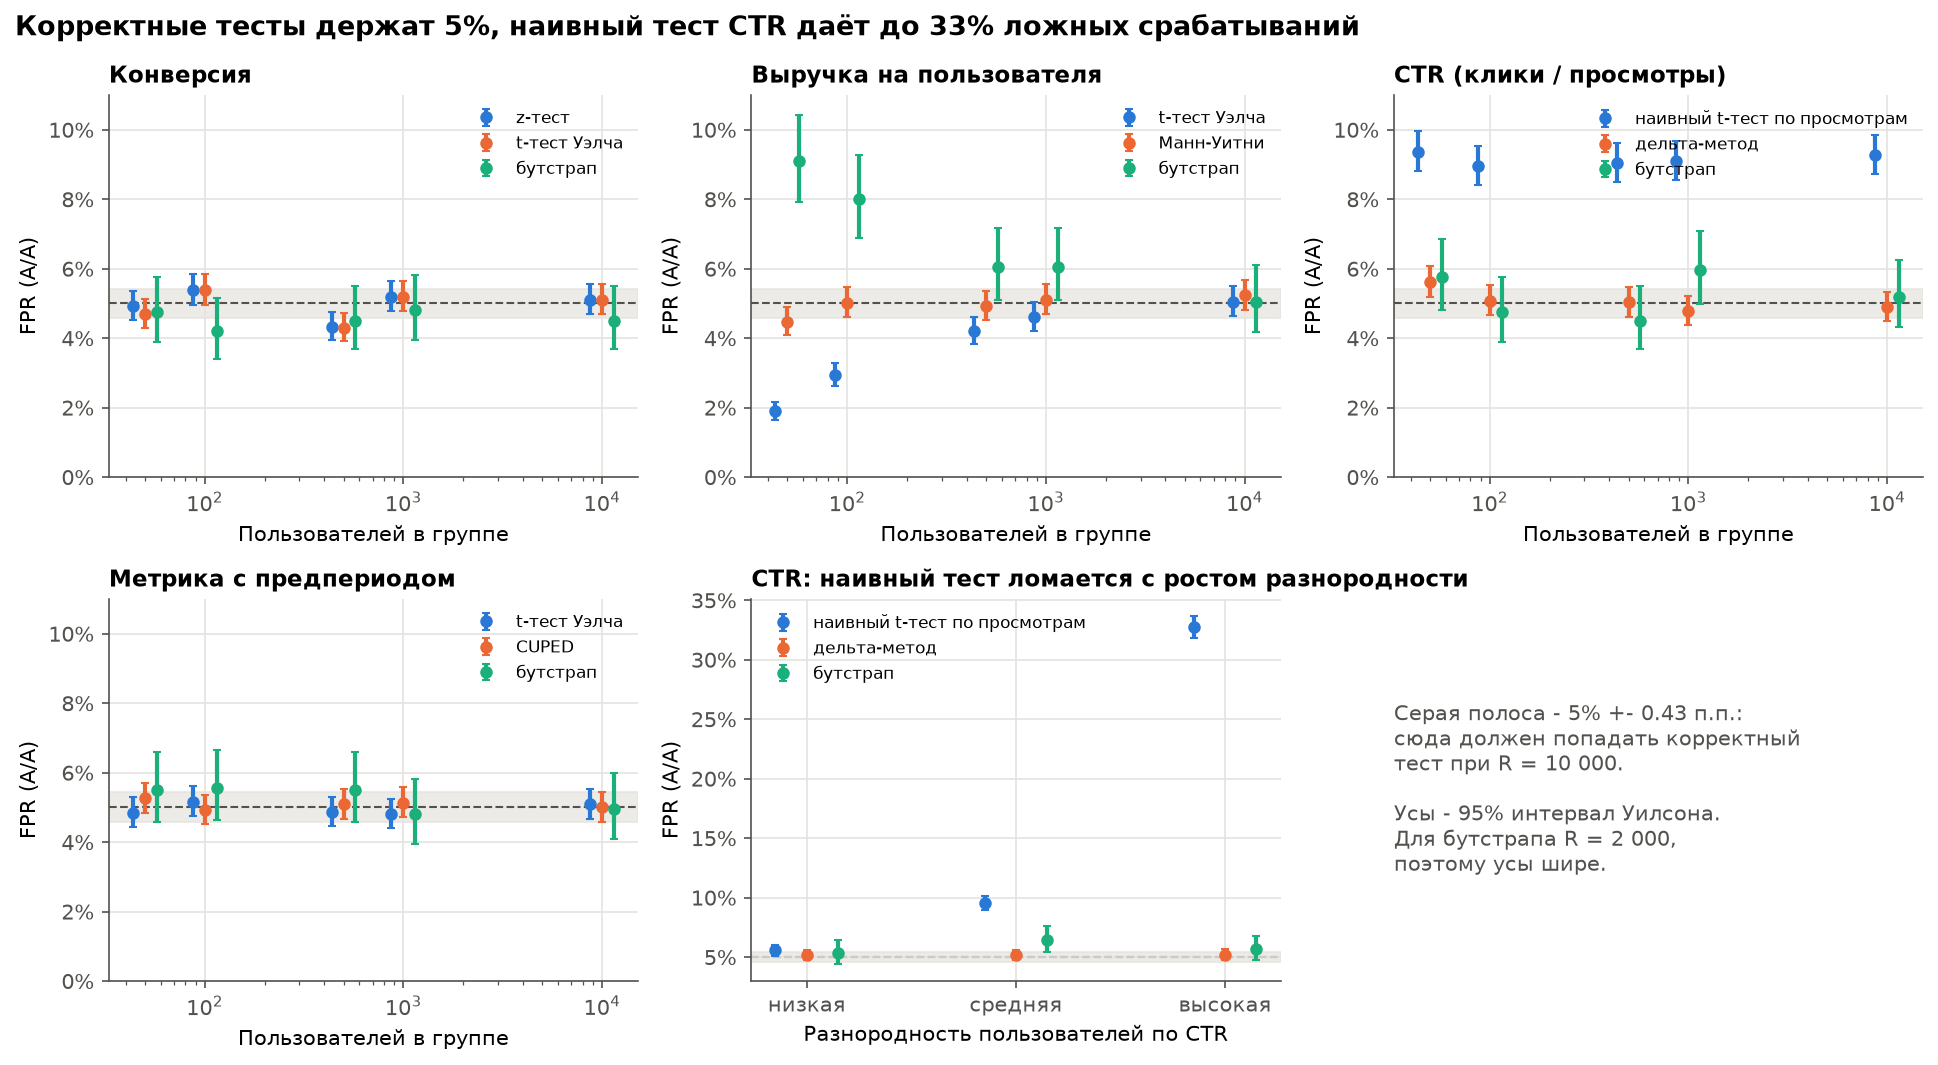

In [3]:
show('fpr_by_test')

Итого по A/A:

- Конверсия: z-тест, t-тест и бутстрап держат 5% при любом n, даже при 50 пользователях.
- Выручка (90% нулей + тяжёлый хвост): на малых n t-тест становится консервативным
  (1,9% при n = 50, 2,9% при n = 100), а перцентильный бутстрап - наоборот, либеральным
  (9,1% и 8,0%). К n = 10 000 оба выходят на 5%. Манн-Уитни держит 5% везде.
- CTR: наивный t-тест по просмотрам даёт ~9% ложных срабатываний при любом n - ошибка не
  уходит с ростом выборки, потому что неверна сама модель дисперсии. Дельта-метод держит 5%.
- CUPED не раздувает FPR: 5% при всех n.

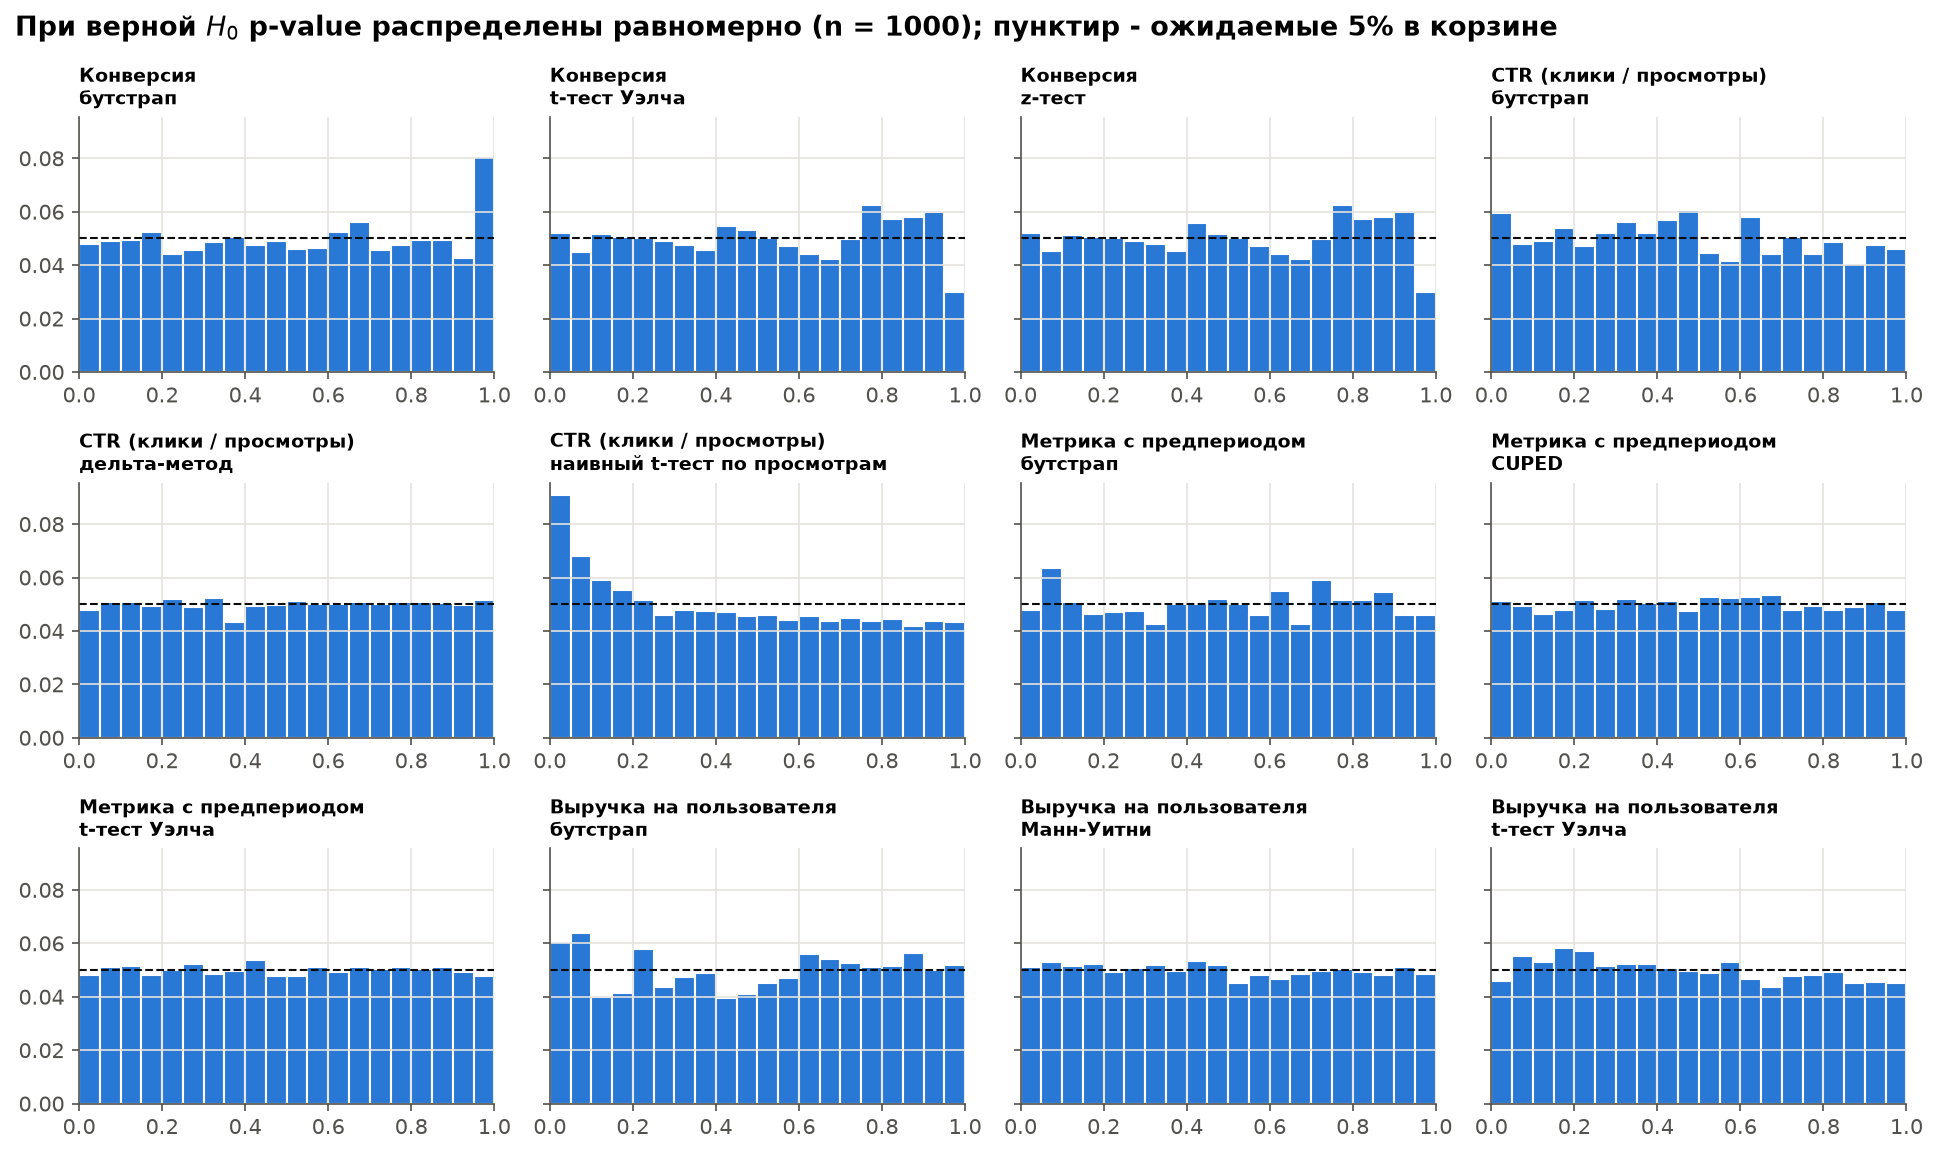

In [4]:
show('pvalue_histograms')

При верной $H_0$ p-value распределены равномерно: в каждой корзине шириной 0,05 около 5%
экспериментов. Перекос к нулю означает лишние ложные срабатывания, перекос к единице -
слишком консервативный тест.

## 2. Мощность и размер выборки

Конверсия 10%, относительный эффект 2-20%. Точки - доля найденных эффектов в симуляции,
пунктир - теоретическая мощность z-теста.

In [5]:
print("Нужно на группу для +10% (0,10 -> 0,11):", power.required_sample_size(0.10, 0.10))
print("Нужно на группу для +5%  (0,10 -> 0,105):", power.required_sample_size(0.10, 0.05))
db.query("simulations/03_min_n_for_power", con)

Нужно на группу для +10% (0,10 -> 0,11): 14749
Нужно на группу для +5%  (0,10 -> 0,105): 57760


,uplift,min_n_power_80,max_power_in_grid
0,0.02,<NA>,0.1863
1,0.05,<NA>,0.7439
2,0.10,20000,0.9994
3,0.20,5000,1.0000


In [6]:
pw = rates.query("scenario == 'power'").copy()
pw["theory"] = power.power_two_proportions(0.10, pw["uplift"], pw["n_per_group"])
pw["inside_ci"] = pw["theory"].between(pw["ci_low"], pw["ci_high"])
print("Теория внутри 95% интервала симуляции:", pw["inside_ci"].mean().round(3))
pw[["uplift", "n_per_group", "rate", "ci_low", "ci_high", "theory"]]

Теория внутри 95% интервала симуляции: 0.964


,uplift,n_per_group,rate,ci_low,ci_high,theory
161,0.02,500,0.0509,0.0468,0.0554,0.0513
162,0.05,500,0.0617,0.0572,0.0666,0.0578
163,0.10,500,0.0835,0.0782,0.0891,0.0810
164,0.20,500,0.1728,0.1655,0.1803,0.1728
165,0.02,1000,0.0505,0.0464,0.0550,0.0525
166,0.05,1000,0.0642,0.0596,0.0692,0.0657
167,0.10,1000,0.1167,0.1106,0.1231,0.1128
168,0.20,1000,0.3025,0.2936,0.3116,0.2984
169,0.02,2000,0.0539,0.0496,0.0585,0.0551
170,0.05,2000,0.0821,0.0769,0.0876,0.0817


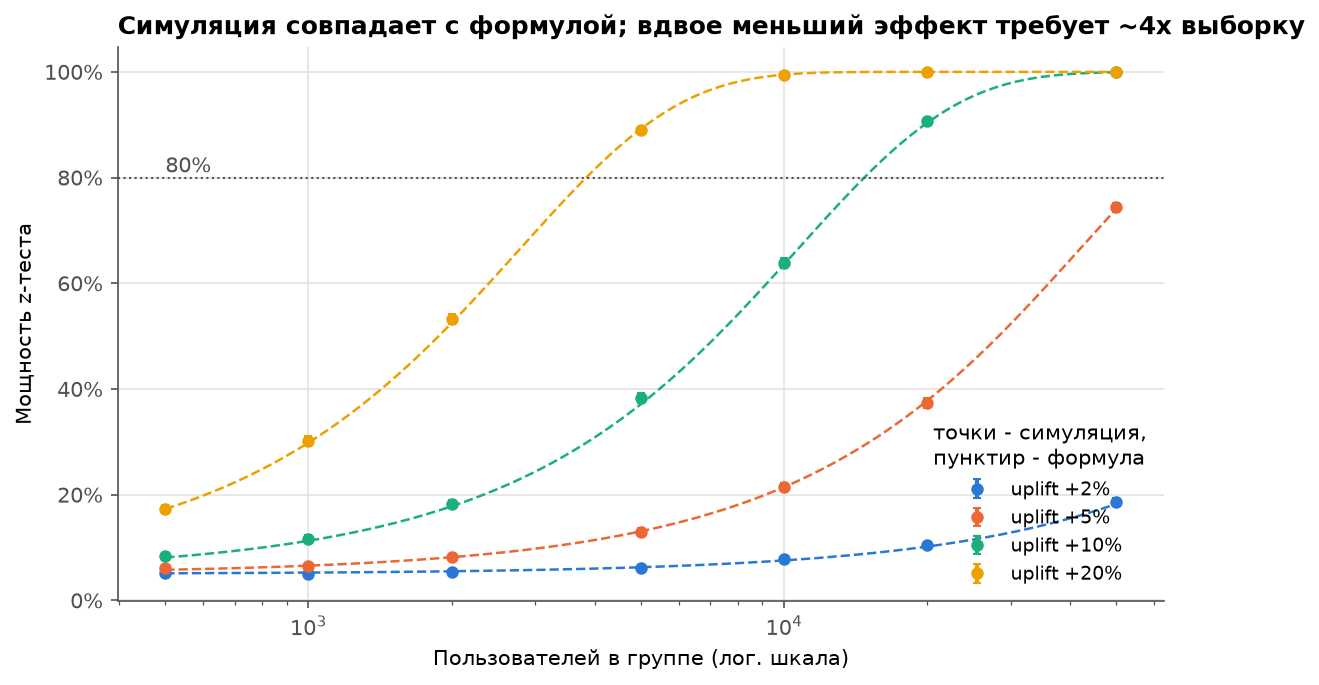

In [7]:
show('power_curves')

Симуляция совпадает с формулой - теория попадает в 95% интервал симуляции
почти во всех точках. Для эффекта +10% (с 0,10 до 0,11) нужно около 14 750 пользователей на группу,
для +5% - уже около 57 760: **вдвое меньший эффект требует примерно вчетверо больше выборку**,
потому что $n \propto 1 / \Delta^2$. Эффект +2% на такой сетке не ловится даже при 50 000 на группу
(мощность 19%).

## 3. Peeking - подглядывание в результаты

20 000 пользователей на группу, K промежуточных проверок через равные промежутки,
тест останавливаем при первом p < 0,05. Исправления: постоянная граница Покока
и граница О'Брайена-Флеминга (строгая в начале, мягкая в конце). Границы считаются
численно (рекурсивное интегрирование), значения совпадают с таблицами.

In [8]:
pd.DataFrame({
    "K": [2, 5, 10, 20, 50],
    "Покок |z| >": [corrections.pocock_boundary(k) for k in (2, 5, 10, 20, 50)],
    "О'Брайен-Флеминг, C": [corrections.obrien_fleming_constant(k) for k in (2, 5, 10, 20, 50)],
})

,K,Покок |z| >,"О'Брайен-Флеминг, C"
0,2,2.1788,1.9799
1,5,2.4134,2.0415
2,10,2.5545,2.0871
3,20,2.6721,2.1254
4,50,2.7972,2.1645


In [9]:
pk = rates.query("scenario == 'peeking'").copy()
pk["K"] = pk["param"].str.extract(r"looks=(\d+)")[0].astype(int)
pk.pivot_table(index="K", columns=["uplift", "test"], values="rate")

uplift    0.00                           0.08                       
test     naive obrien_fleming  pocock   naive obrien_fleming  pocock
K                                                                   
1       0.0523         0.0523  0.0523  0.7545         0.7545  0.7545
2       0.0795         0.0475  0.0504  0.7679         0.7367  0.6949
5       0.1373         0.0492  0.0490  0.8075         0.7380  0.6530
10      0.2004         0.0519  0.0497  0.8275         0.7272  0.6186
20      0.2495         0.0524  0.0507  0.8496         0.7282  0.5879
50      0.3248         0.0518  0.0525  0.8664         0.7310  0.5677

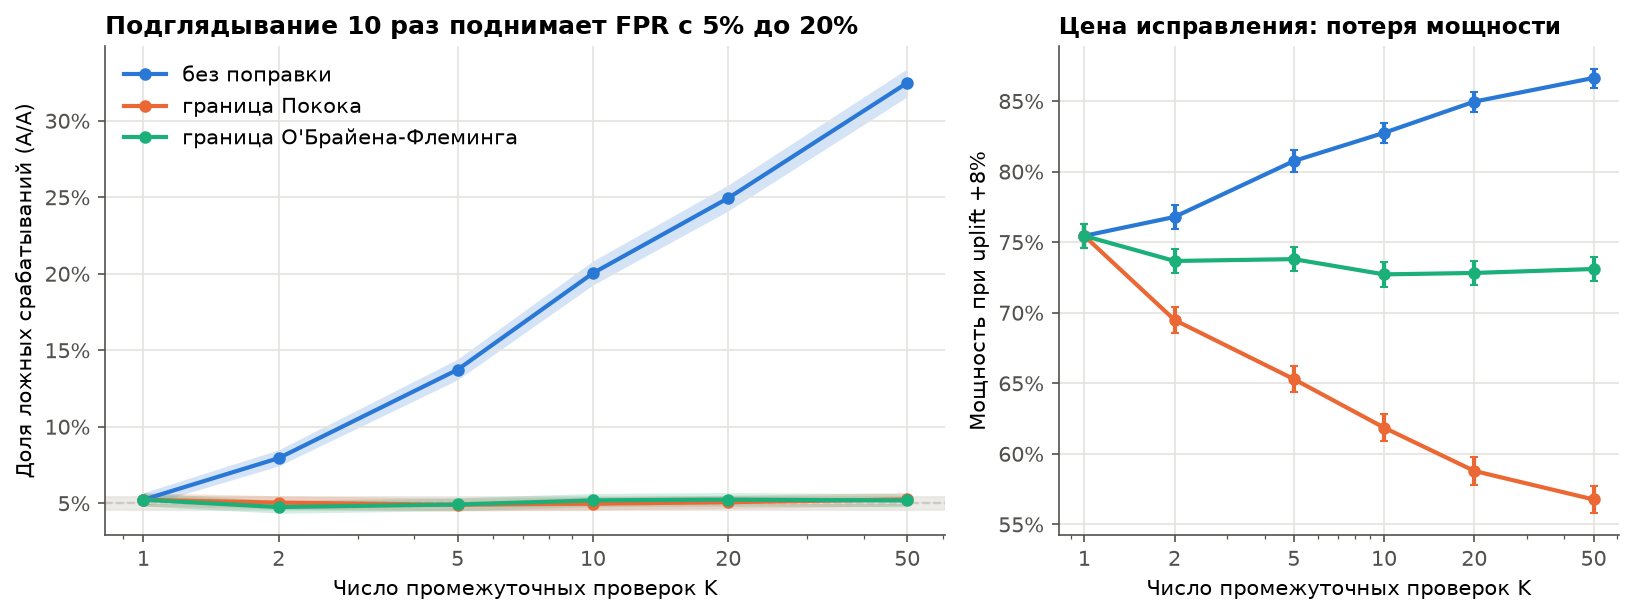

In [10]:
show('peeking_fpr')

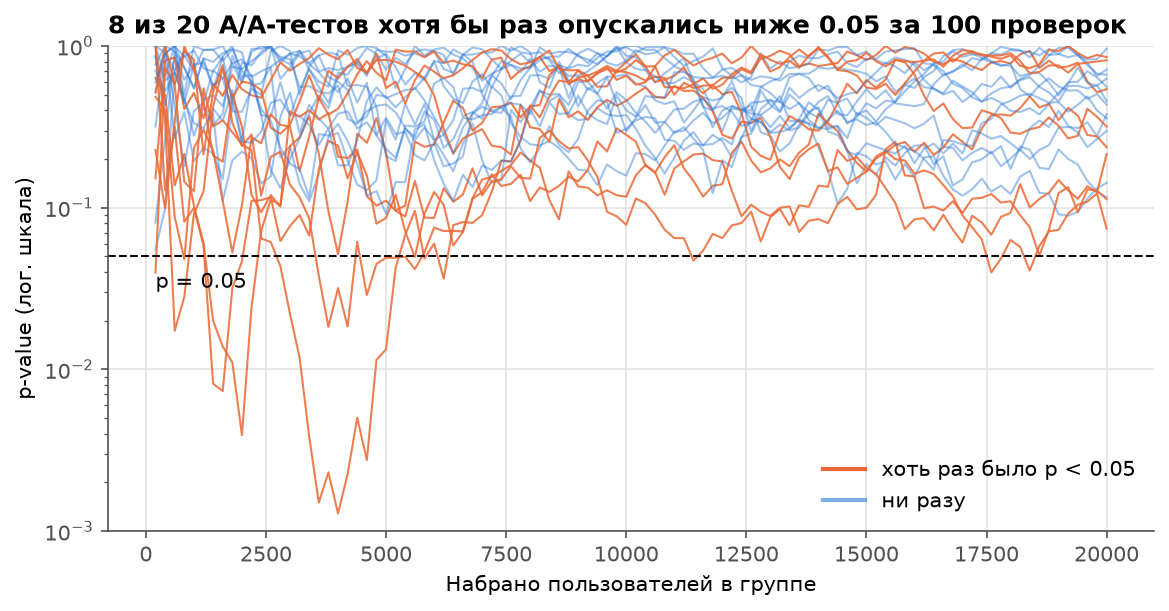

In [11]:
show('pvalue_trajectories')

При 10 подглядываниях доля ложных срабатываний растёт с 5% до 20%, при 50 -
до 32%. На траекториях видно, как p-value A/A-тестов "гуляют" и случайно опускаются ниже 0,05,
а потом снова поднимаются: если остановиться в такой момент, получится ложная находка.

Обе границы возвращают FPR к 5%. Цена разная: с границей Покока при 10 проверках мощность
падает с 75% до 62%, с границей О'Брайена-Флеминга - только до 73%, потому что она почти
не тратит $\alpha$ на ранних проверках. На практике, если промежуточные проверки нужны,
лучше брать О'Брайена-Флеминга.

## 4. Тяжёлые хвосты (выручка)

Выручка = конверсия 10%, умноженная на логнормальный чек, n = 5 000 на группу, эффект +15% к среднему чеку.
Сравниваем t-тест, бутстрап, Манна-Уитни, t-тест на log(1 + x) и t-тест с отсечением
значений выше 99-го перцентиля.

In [12]:
ht = rates.query("scenario == 'heavy_tails' and metric == 'revenue'").copy()
ht["sigma"] = ht["param"].str.extract(r"sigma=([\d.]+)")[0].astype(float)
ht.pivot_table(index=["uplift", "test"], columns="sigma", values="rate")

sigma                   0.5     1.0     1.5     2.0
uplift test                                        
0.00   bootstrap     0.0540  0.0505  0.0535  0.0655
       log_t         0.0451  0.0509  0.0528  0.0510
       mann_whitney  0.0451  0.0505  0.0514  0.0491
       welch_t       0.0438  0.0503  0.0457  0.0385
       winsorized_t  0.0452  0.0497  0.0511  0.0498
0.15   bootstrap     0.5090  0.2935  0.1405  0.1155
       log_t         0.0645  0.0648  0.0619  0.0660
       mann_whitney  0.0560  0.0512  0.0492  0.0511
       welch_t       0.5332  0.2789  0.1287  0.0663
       winsorized_t  0.4281  0.2613  0.1686  0.1147

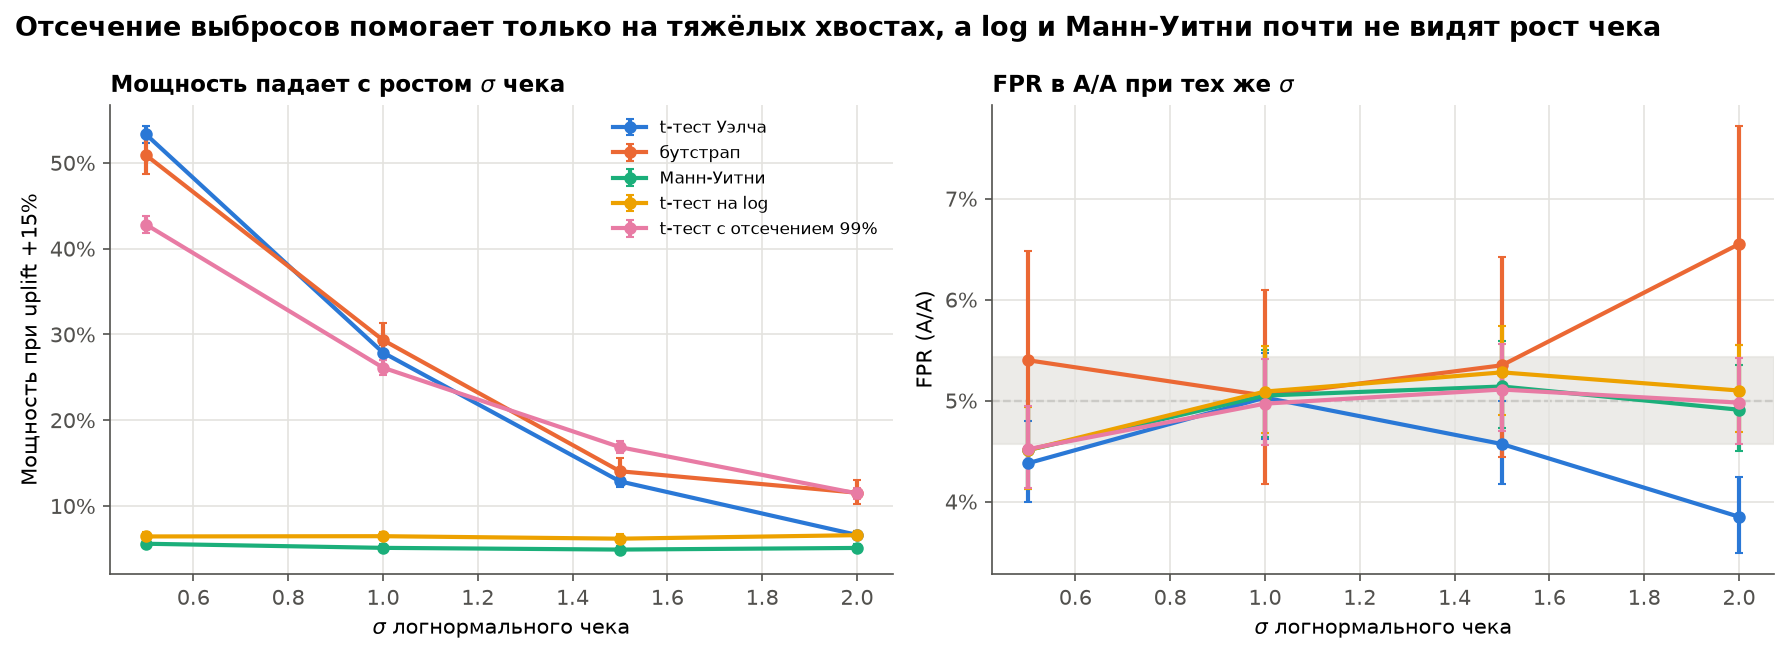

In [13]:
show('heavy_tails_power')

**Ловушка для Манна-Уитни.** Средняя выручка в группах одинаковая, но в B у чека больше
разброс: больше мелких покупок и изредка очень крупные.

In [14]:
rates.query("scenario == 'heavy_tails' and metric == 'revenue_shape'")[["test", "rate", "ci_low", "ci_high"]]

,test,rate,ci_low,ci_high
120,bootstrap,0.0815,0.0703,0.0943
121,log_t,0.7140,0.7051,0.7228
122,mann_whitney,0.0809,0.0757,0.0864
123,welch_t,0.0832,0.0779,0.0888
124,winsorized_t,0.9776,0.9745,0.9803


Что получилось:

- Мощность t-теста быстро падает с ростом $\sigma$ чека: 53% при $\sigma = 0.5$ и 7% при $\sigma = 2$.
  Бутстрап ведёт себя так же - он тоже сравнивает средние.
- Отсечение выбросов выше 99-го перцентиля при $\sigma = 0.5$ проигрывает (43%), а при $\sigma \ge 1.5$
  выигрывает (17% против 13%, 12% против 7%).
- t-тест на логарифме и Манн-Уитни почти не видят рост чека (5-7%): у 90% пользователей
  выручка нулевая, эффект есть только у платящих, и ранги почти не меняются.
- В ловушке (средняя выручка одинаковая) t-тест на логарифме "находит" эффект в 71% случаев,
  отсечение - в 98%. Это не ошибка теста: они проверяют другую величину, не среднюю выручку.
  Манн-Уитни здесь ошибается реже (8%) только потому, что нули размывают и его.

**Вывод:** "лучшего" теста нет. t-тест и бутстрап проверяют именно среднюю выручку,
но на тяжёлых хвостах им нужно много данных. Отсечение и логарифм мощнее на хвостах,
но меняют гипотезу - это нужно решать до теста и прописывать в дизайне.

## 5. Метрики-отношения (CTR)

CTR = клики / просмотры по всей группе. У каждого пользователя своя вероятность клика
(Бета-распределение со средним 5%). Разнородность задаётся концентрацией a + b:
400 (низкая), 40 (средняя), 4 (высокая). n = 2 000 пользователей на группу.

In [15]:
rt = rates.query("scenario == 'ratio'").copy()
rt["level"] = rt["param"].str.extract(r"heterogeneity=(\w+)")[0]
rt.pivot_table(index=["uplift", "test"], columns="level", values="rate")[["low", "medium", "high"]]

level                low  medium    high
uplift test                             
0.0    bootstrap  0.0535  0.0645  0.0565
       delta      0.0516  0.0517  0.0521
       naive_t    0.0556  0.0955  0.3272
0.1    bootstrap  0.6065  0.4805  0.2000
       delta      0.5918  0.4724  0.2009
       naive_t    0.6080  0.5882  0.5744

In [16]:
cov = db.query("simulations/06_ci_coverage", con).query("scenario == 'ratio'").copy()
cov["level"] = cov["setting"].str.extract(r"heterogeneity=(\w+)")[0]
cov.pivot_table(index=["uplift", "test"], columns="level", values="coverage")[["low", "medium", "high"]]

level                low  medium    high
uplift test                             
0.0    bootstrap  0.9435  0.9330  0.9425
       delta      0.9484  0.9483  0.9479
       naive_t    0.9444  0.9045  0.6728
0.1    bootstrap  0.9425  0.9480  0.9425
       delta      0.9526  0.9474  0.9472
       naive_t    0.9479  0.9019  0.6606

Наивный тест по просмотрам недооценивает дисперсию, и чем разнороднее
пользователи, тем сильнее: FPR 5,5% при низкой разнородности, 9,6% при средней и 33%
при высокой. Его 95% интервалы накрывают истинную разницу только в 67% случаев.
Дельта-метод держит 5% и покрытие ~95% во всех вариантах. Бутстрап по пользователям близок
к нему (покрытие 93-95%), но на n = 2 000 слегка либерален.

Высокая "мощность" наивного теста при uplift = 10% - не преимущество, а следствие того же
занижения дисперсии.

## 6. CUPED

Метрика во время теста Y и та же метрика до теста X с корреляцией $\rho$.
n = 1 000 на группу, эффект +2% к среднему.

In [17]:
db.query('simulations/05_cuped_variance', con)

,rho,uplift,reps,var_ratio,var_ratio_low,var_ratio_high,var_ratio_theory,rate_plain,rate_cuped
0,0.0,0.00,10000,0.9989,0.9605,1.0388,1.00,0.0499,0.0503
1,0.3,0.00,10000,0.9070,0.8721,0.9432,0.91,0.0545,0.0519
2,0.5,0.00,10000,0.7539,0.7249,0.7840,0.75,0.0495,0.0498
3,0.7,0.00,10000,0.5046,0.4852,0.5247,0.51,0.0490,0.0490
4,0.9,0.00,10000,0.1892,0.1819,0.1968,0.19,0.0507,0.0521
5,0.0,0.02,10000,0.9994,0.9609,1.0393,1.00,0.6133,0.6132
6,0.3,0.02,10000,0.9124,0.8774,0.9489,0.91,0.6124,0.6548
7,0.5,0.02,10000,0.7414,0.7129,0.7711,0.75,0.6069,0.7283
8,0.7,0.02,10000,0.5104,0.4908,0.5308,0.51,0.5983,0.8715
9,0.9,0.02,10000,0.1889,0.1816,0.1964,0.19,0.6138,0.9991


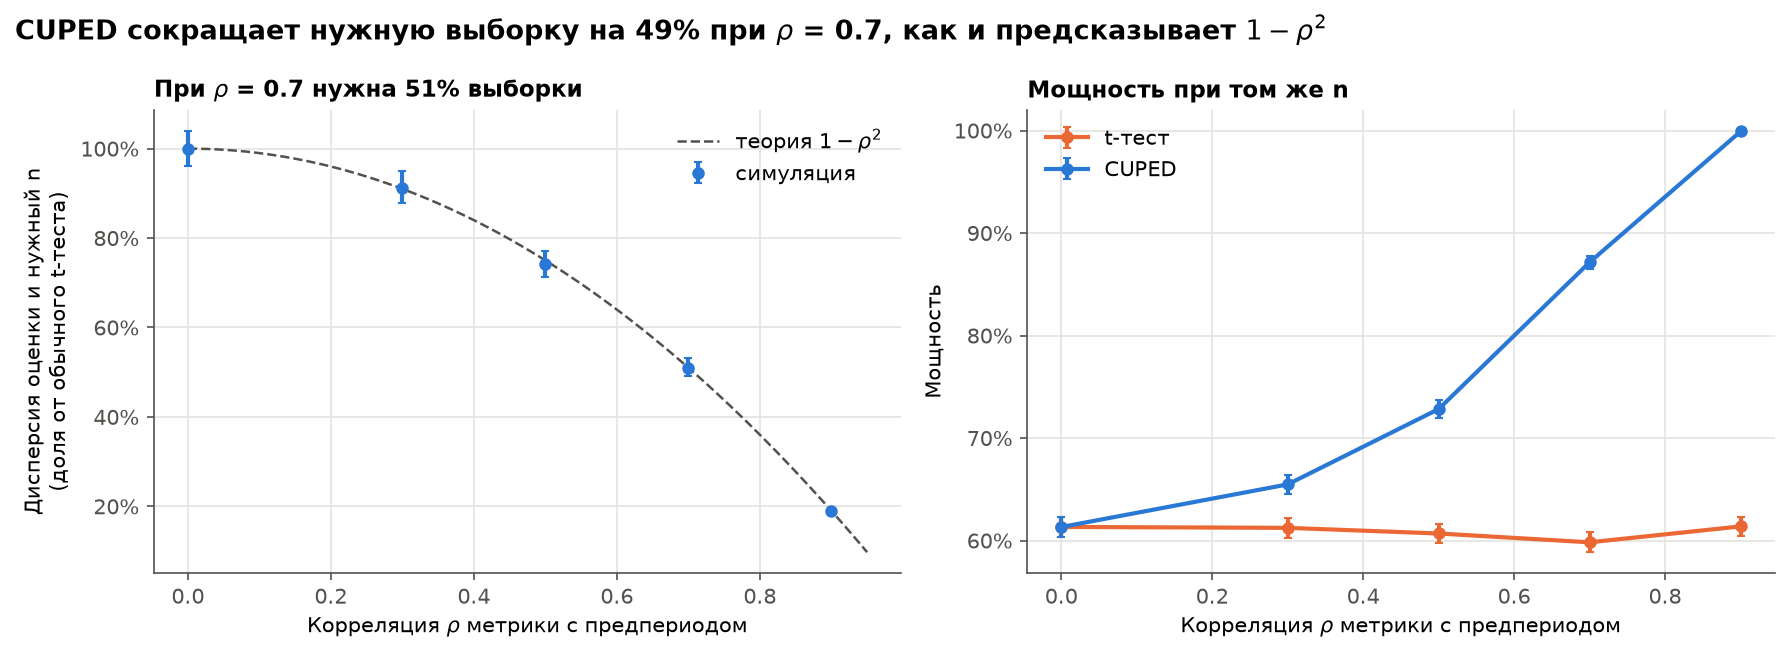

In [18]:
show('cuped_savings')

Дисперсия оценки эффекта падает ровно как $1 - \rho^2$: при $\rho = 0.7$ остаётся 51%
(теория - 51%), при $\rho = 0.9$ - 19%. Значит, **при $\rho = 0.7$ CUPED позволяет взять почти вдвое
меньшую выборку** (-49%). При том же n мощность растёт с 60% до 87%. FPR с CUPED остаётся 5%,
потому что $\theta$ считается по обеим группам вместе и поправка не смещает оценку.

## 7. Множественное тестирование

k метрик, n = 1 000 на группу. Сначала у всех метрик эффекта нет, затем эффект есть
у 2 из 10 (сдвиг 0,125 стандартного отклонения, мощность одного теста около 80%).

In [19]:
mt = db.query("simulations/04_fwer_fdr", con)
mt.pivot_table(index=["n_true", "rho", "test"], columns="k", values="fwer")

k                          1       5       10      20
n_true rho test                                      
0      0.0 bh          0.0512  0.0495  0.0514  0.0530
           bonferroni  0.0512  0.0487  0.0506  0.0513
           holm        0.0512  0.0487  0.0506  0.0513
           none        0.0512  0.2190  0.4006  0.6446
       0.5 bh          0.0478  0.0428  0.0425  0.0413
           bonferroni  0.0478  0.0401  0.0392  0.0368
           holm        0.0478  0.0401  0.0392  0.0368
           none        0.0478  0.1784  0.2867  0.4212
2      0.0 bh             NaN     NaN  0.0882     NaN
           bonferroni     NaN     NaN  0.0393     NaN
           holm           NaN     NaN  0.0441     NaN
           none           NaN     NaN  0.3447     NaN
       0.5 bh             NaN     NaN  0.0657     NaN
           bonferroni     NaN     NaN  0.0299     NaN
           holm           NaN     NaN  0.0341     NaN
           none           NaN     NaN  0.2529     NaN

In [20]:
mt.query("n_true == 2")[["rho", "test", "fwer", "fdr", "power"]]

,rho,test,fwer,fdr,power
32,0.0,bh,0.0882,0.0405,0.5537
33,0.0,bonferroni,0.0393,0.0229,0.4936
34,0.0,holm,0.0441,0.0245,0.5008
35,0.0,none,0.3447,0.1520,0.7973
36,0.5,bh,0.0657,0.0366,0.5454
37,0.5,bonferroni,0.0299,0.0208,0.4907
38,0.5,holm,0.0341,0.0225,0.4978
39,0.5,none,0.2529,0.1360,0.7974


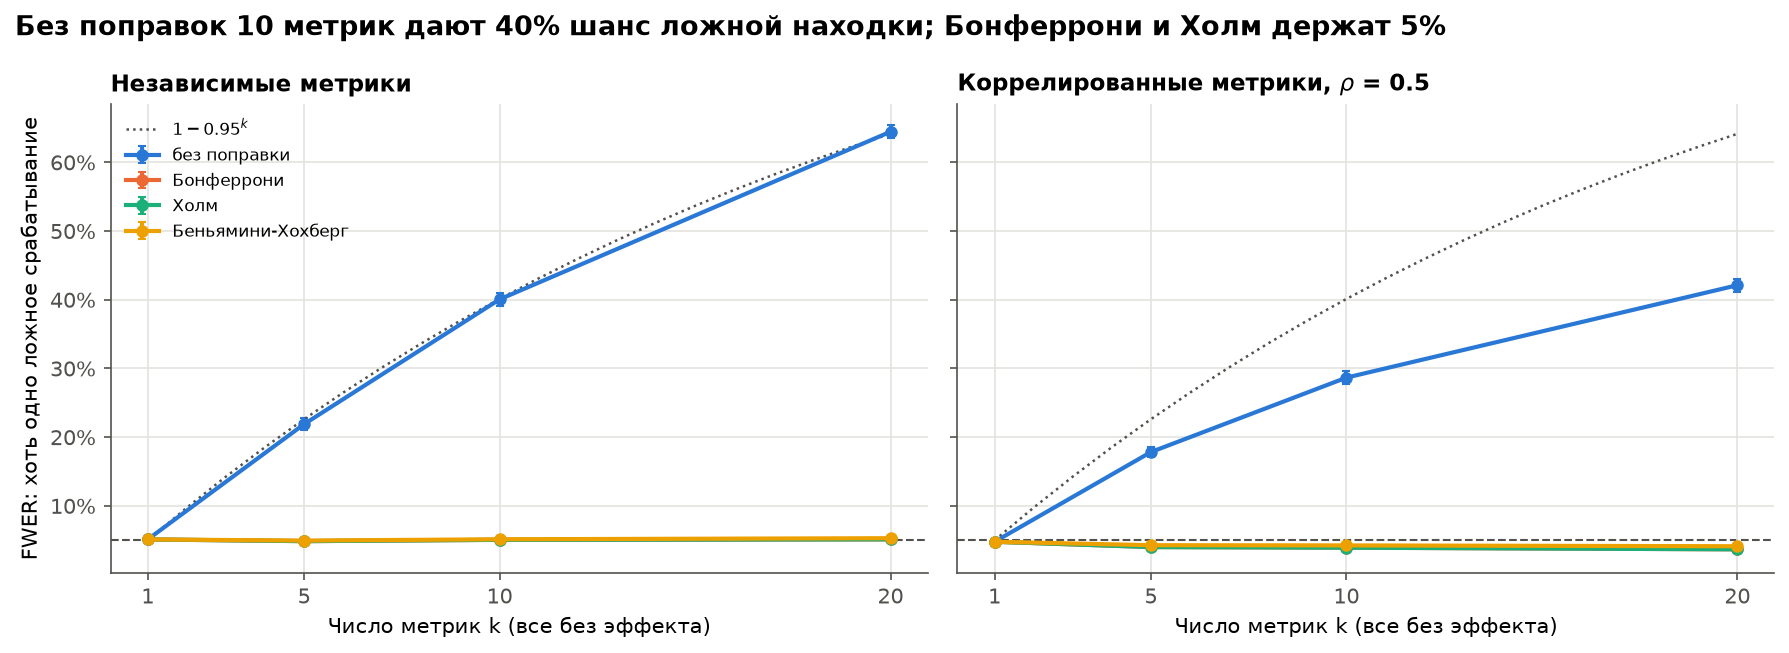

In [21]:
show('multiple_testing')

**Что видно:**

- Без поправок вероятность хотя бы одной ложной находки на 10 независимых метриках - 40%
  (формула $1 - 0.95^{10} = 40\%$), на 20 метриках - 64%.
- Бонферрони и Холм держат FWER $\le$ 5%. На коррелированных метриках ($\rho = 0.5$) - с запасом
  (3,7% при k = 20), то есть теряют мощность: поправка рассчитана на худший случай.
- Холм всегда не слабее Бонферрони: мощность по настоящим эффектам 50,1% против 49,4%.
- Беньямини-Хохберг контролирует не FWER, а FDR: FWER у него 8,8%, но доля ложных среди
  найденных - 4%, а мощность заметно выше (55%).

## 8. SRM - сломанное разбиение

Сначала просто перекос долей: как часто хи-квадрат ловит его при пороге p < 0,001.

In [22]:
srm = rates.query("scenario == 'srm' and metric == 'split'").copy()
srm[["N", "share_b"]] = srm["param"].str.extract(r"N=(\d+);share_b=([\d.]+)").astype(float)
srm.pivot_table(index="share_b", columns="N", values="rate")

N,10000.0,100000.0,1000000.0
share_b,,,
0.500,0.0016,0.0006,0.0009
0.505,0.0115,0.4434,1.0000
0.510,0.0954,0.9989,1.0000
0.520,0.7702,1.0000,1.0000


Теперь откуда берётся перекос на практике: из B выпадают малоактивные пользователи
(например, у них не загрузилась новая версия). Тест - A/A, по-настоящему группы не различаются.

In [23]:
db.query('simulations/08_srm_dropout', con)

,drop_rate,test,reps,rate,ci_low,ci_high,rate_at_005,mean_effect
0,0.00,chi2,10000,0.0000,0.0000,0.0004,0.0000,NaN
1,0.00,welch_t,10000,0.0526,0.0484,0.0571,0.0526,-0.0026
2,0.01,chi2,10000,0.0000,0.0000,0.0004,0.0000,NaN
3,0.01,welch_t,10000,0.0672,0.0625,0.0723,0.0672,0.0945
4,0.02,chi2,10000,0.0000,0.0000,0.0004,0.0000,NaN
5,0.02,welch_t,10000,0.1388,0.1322,0.1457,0.1388,0.1933
6,0.04,chi2,10000,0.0000,0.0000,0.0004,1.0000,NaN
7,0.04,welch_t,10000,0.4130,0.4034,0.4227,0.4130,0.3993
8,0.08,chi2,10000,1.0000,0.9996,1.0000,1.0000,NaN
9,0.08,welch_t,10000,0.9426,0.9379,0.9470,0.9426,0.8305


Перекос 50,5 / 49,5 при 10 000 пользователей не виден совсем, при 100 000
($\chi^2 \approx 10$, $p \approx 0.002$) ловится по порогу 0,001 только в 44% случаев, при 1 000 000 - всегда.
Порог 0,001 выбран строже обычного, потому что SRM проверяют в каждом эксперименте и ложная
тревога тоже стоит дорого.

Главное - вторая таблица. Если из B выпало всего 4% пользователей, причём малоактивных,
A/A-тест "находит" рост активности в 41% случаев, а хи-квадрат по порогу 0,001 этого ещё не
видит. При 8% выпавших ложный рост - в 94% экспериментов. SRM - это не косметика: выпадение
неслучайных пользователей сдвигает метрику в группе.

## 9. SQL по результатам симуляций

Рейтинг критериев по мощности в каждой точке сценария - оконная функция `RANK()`.

In [24]:
db.query('simulations/02_test_ranking', con)

,scenario,metric,test,n_per_group,uplift,setting,power,power_rank
0,cuped,pre_period,welch_t,1000,0.02,rho=0.0,0.6133,1
1,cuped,pre_period,cuped,1000,0.02,rho=0.0,0.6132,2
2,cuped,pre_period,cuped,1000,0.02,rho=0.3,0.6548,1
3,cuped,pre_period,welch_t,1000,0.02,rho=0.3,0.6124,2
4,cuped,pre_period,cuped,1000,0.02,rho=0.5,0.7283,1
5,cuped,pre_period,welch_t,1000,0.02,rho=0.5,0.6069,2
6,cuped,pre_period,cuped,1000,0.02,rho=0.7,0.8715,1
7,cuped,pre_period,welch_t,1000,0.02,rho=0.7,0.5983,2
8,cuped,pre_period,cuped,1000,0.02,rho=0.9,0.9991,1
9,cuped,pre_period,welch_t,1000,0.02,rho=0.9,0.6138,2


## 10. Реальный тест: Cookie Cats

90 189 игроков мобильной игры. В контрольной группе `gate_30` первые "ворота" (вынужденная
пауза) стоят на 30-м уровне, в `gate_40` - на 40-м. Метрики: удержание на 1-й и 7-й день
и число сыгранных раундов за 14 дней.

In [25]:
db.query('cookie_cats/01_group_sizes_srm', con)

,version,players,share,chi2,p_value,srm_detected
0,gate_30,44700,0.4956,6.9024,0.0086,False
1,gate_40,45489,0.5044,6.9024,0.0086,False


Групп почти поровну: 44 700 против 45 489, $\chi^2 = 6.9$, $p = 0.009$. По индустриальному порогу
0,001 это не SRM, но перекос стоит держать в голове.

In [26]:
db.query('cookie_cats/02_retention', con)

,metric,version,n,rate,se,ci_low,ci_high
0,retention_1,gate_30,44700,0.4482,0.0024,0.4436,0.4528
1,retention_1,gate_40,45489,0.4423,0.0023,0.4377,0.4469
2,retention_7,gate_30,44700,0.1902,0.0019,0.1866,0.1938
3,retention_7,gate_40,45489,0.1820,0.0018,0.1784,0.1855


In [27]:
db.query('cookie_cats/03_rounds_distribution', con)

,version,players,share_zero_rounds,mean_rounds,p25,median,p75,p90,p99,max_rounds,outlier_threshold,outliers
0,gate_30,44700,0.0433,52.4563,5.0,17.0,50.0,135.0,493.00,49854,185.0,2941
1,gate_40,45489,0.0452,51.2988,5.0,16.0,52.0,134.0,492.12,2640,193.0,2777


Распределение раундов очень скошено: медиана 16-17, 99-й перцентиль ~490, у ~4,4% игроков
0 раундов. В `gate_30` есть аномальный игрок с 49 854 раундами (следующий максимум - 2 640),
он сильно влияет на среднее и дисперсию - поэтому для раундов t-тест малоинформативен.

In [28]:
db.query('cookie_cats/04_activity_deciles', con)

,decile,rounds_from,rounds_to,ret7_gate_30,ret7_gate_40,diff,rank_abs_diff
0,1,0,1,0.0076,0.0068,-0.0008,10
1,2,1,4,0.0114,0.0152,0.0038,7
2,3,4,6,0.0208,0.0198,-0.0010,8
3,4,6,11,0.0345,0.0295,-0.0050,5
4,5,11,17,0.0579,0.0541,-0.0039,6
5,6,17,26,0.0993,0.0871,-0.0123,4
6,7,26,40,0.1512,0.1378,-0.0134,3
7,8,40,66,0.2765,0.2458,-0.0307,1
8,9,66,135,0.4669,0.4493,-0.0176,2
9,10,135,49854,0.7758,0.7748,-0.0010,9


Сильнее всего группы различаются в 8-м дециле (40-66 раундов): retention 7-го дня 27,5%
против 24,6%. Это игроки, которые как раз доходят до 30-40 уровня. Но число раундов измерено
уже после начала теста и само зависит от версии игры, поэтому такая стратификация может давать
смещение: это повод для гипотезы, а не вывод.

In [29]:
cum = db.query("cookie_cats/05_cumulative_retention", con)
cum.iloc[::4]

,players_per_group,ret7_gate_30,ret7_gate_40,z,p_value
0,1000,0.2000,0.1720,-1.6091,0.1076
4,5000,0.1940,0.1774,-2.1344,0.0328
8,9000,0.1912,0.1832,-1.3757,0.1689
12,13000,0.1905,0.1846,-1.2233,0.2212
16,17000,0.1897,0.1829,-1.6020,0.1092
20,21000,0.1909,0.1827,-2.1533,0.0313
24,25000,0.1917,0.1814,-2.9621,0.0031
28,29000,0.1916,0.1822,-2.9080,0.0036
32,33000,0.1910,0.1829,-2.6659,0.0077
36,37000,0.1905,0.1826,-2.7461,0.0060


Порядок по `userid` условный (времени прихода в данных нет). Видно, как было бы опасно
подглядывать: p-value то опускается ниже 0,05 (впервые уже на 5 000 игроков в группе),
то поднимается обратно. Итог на всей выборке при этом устойчивый.

In [30]:
players = cc.load()
rng = np.random.default_rng(2026)
cc.final_tests(players, rng)

,metric,test,p_value,effect,ci_low,ci_high
0,retention_1,z_test,0.0744,-0.0059,-0.0124,0.0006
1,retention_1,bootstrap,0.0756,-0.0059,-0.0124,0.0005
2,retention_7,z_test,0.0016,-0.0082,-0.0133,-0.0031
3,retention_7,bootstrap,0.0012,-0.0082,-0.0132,-0.0032
4,sum_gamerounds,welch_t,0.3759,-1.1575,-3.7197,1.4047
5,sum_gamerounds,mann_whitney,0.0502,0.4962,NaN,NaN


In [31]:
cc.shuffled_aa(players, rng, n_reps=2000)

,metric,test,reps,fpr,ci_low,ci_high
0,retention_1,z_test_proportions,2000,0.052,0.0431,0.0626
1,retention_7,z_test_proportions,2000,0.055,0.0458,0.0659
2,sum_gamerounds,welch_t,2000,0.017,0.0122,0.0237


**Вывод по тесту.** Перенос ворот с 30-го на 40-й уровень снижает удержание на 7-й день
на 0,82 п.п. (с 19,0% до 18,2%, 95% интервал от -1,3 до -0,3 п.п., p = 0,002; z-тест и бутстрап
совпадают). Удержание 1-го дня тоже ниже на 0,6 п.п., но это в пределах шума (p = 0,07).
A/A-проверка на перемешанных метках даёт ~5% ложных срабатываний для retention - z-тест
на этих данных работает корректно. Для числа раундов t-тест срабатывает только в 1,7% случаев:
из-за аномального игрока с 49 854 раундами дисперсия раздута и тест слишком консервативен
(та же картина, что в сценарии 4 на тяжёлых хвостах).

**Рекомендация продукту:** оставить ворота на 30-м уровне. Перенос не даёт выигрыша
в активности и снижает недельное удержание, а это ключевая метрика для монетизации.

## 11. Производительность

In [32]:
pd.read_csv('../results/benchmark.csv')

,n,reps,method,seconds,speedup,cpu
0,1000,100000,Цикл Python по повторениям,21.7488,1.0000,AMD Ryzen 7 5700U with Radeon Graphics
1,1000,100000,Векторизация NumPy,12.1113,1.7958,AMD Ryzen 7 5700U with Radeon Graphics
2,1000,100000,Векторизация + 4 процесса,4.9975,4.3519,AMD Ryzen 7 5700U with Radeon Graphics
3,10000,10000,Цикл Python по повторениям,7.1409,1.0000,AMD Ryzen 7 5700U with Radeon Graphics
4,10000,10000,Векторизация NumPy,12.5963,0.5669,AMD Ryzen 7 5700U with Radeon Graphics
5,10000,10000,Векторизация + 4 процесса,3.4525,2.0683,AMD Ryzen 7 5700U with Radeon Graphics


Задача - A/A-тесты t-тестом Уэлча на выручке. При n = 1 000 векторизация ускоряет расчёт
в 1,8 раза, а с 4 процессами - в 4,4 раза. При n = 10 000 векторизация сама по себе не
помогает: почти всё время уходит на генерацию случайных чисел, а она одинакова в обоих
подходах; цикл даже немного выигрывает, потому что массив одного эксперимента (80 КБ)
помещается в кэш процессора. Здесь ускоряют только процессы (в 2,1 раза). Для конверсии отдельно
работает приём из сценария 2: генерировать сразу биномиальные суммы, а не n наблюдений.

## Выводы

1. Подглядывание 10 раз поднимает долю ложных срабатываний с 5% до 20%; граница
   О'Брайена-Флеминга возвращает 5%, теряя всего 3 п.п. мощности.
2. Наивный тест CTR по просмотрам даёт до 33% ложных срабатываний; дельта-метод держит 5%.
3. CUPED при корреляции 0,7 с предпериодом сокращает нужную выборку на 49%, ровно как $1 - \rho^2$.
4. Без поправок 10 метрик дают 40% шанс ложной находки; Холм держит 5% и мощнее Бонферрони.
5. Вдвое меньший эффект требует вчетверо большей выборки; для +10% к конверсии 10% нужно
   ~14 750 пользователей на группу - симуляция совпадает с формулой.
6. Выпадение 4% малоактивных пользователей из группы даёт ложный "рост" в 41% A/A-тестов.
7. На выручке нет лучшего теста: логарифм и отсечение выбросов мощнее на хвостах, но проверяют
   уже не среднюю выручку.